# Module 2 · Class 2: asyncio, Centralized Exchanges and CCXT
## From one blockchain node to many exchanges at once

**Learning Objectives:**
- Understand **concurrency** with `asyncio`: why querying *n* exchanges concurrently takes about as long as querying one
- Read public market data from the **Binance.us REST API**: order book and average price
- Understand how **private endpoints are authenticated**: HMAC-SHA256 signature over the query string
- Use **CCXT**, one standard interface for 100+ exchanges (tickers, order books, OHLCV candles)
- Compare **CEX vs DEX** prices: Binance.us / Kraken against SushiSwap and QuickSwap pools on Polygon

**Key Question:** If the same asset trades in many places at once, how do we watch all of them fast enough?

> All data is downloaded live when you run the notebook (public endpoints, no API keys), so prices change on every run. The only cells that need credentials read them from environment variables and skip themselves when they are not set.

---
## 1. Setup & Imports

In [1]:
import os
import time
import json
import hmac
import hashlib
import asyncio
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import ccxt
import ccxt.async_support as ccxt_async
from web3 import Web3
from web3.middleware import ExtraDataToPOAMiddleware

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.float_format', '{:,.4f}'.format)

SYMBOL = "ETH/USDC"   # pair used throughout the notebook
# Exchanges with public ETH/USDC market data reachable without keys (checked live, Oct 2026)
EXCHANGES = ["binanceus", "kraken", "coinbase", "okx", "bybit"]

print("ccxt version:", ccxt.__version__)

ccxt version: 4.5.90


---
## 2. asyncio: concurrent requests

A request to an exchange spends almost all its time **waiting for the network**. Done one after another (synchronously), the total time is the **sum** of the latencies; with `asyncio` we start every request first and then wait for all of them together, so the total is roughly the **slowest single** latency.

`ccxt.async_support` exposes the same methods as `ccxt`, but as coroutines (`await exchange.fetch_ticker(...)`).

### 2a. Synchronous: one exchange after another

In [2]:
def mid_price(ticker):
    # Mid of the best bid and ask; 'last' can be a stale trade on a thin market
    if ticker.get("bid") and ticker.get("ask"):
        return (ticker["bid"] + ticker["ask"]) / 2
    return ticker["last"]


def fetch_mid_sync(exchange_id):
    # Mid price of SYMBOL on one exchange, or None if it does not answer
    exchange = getattr(ccxt, exchange_id)({"timeout": 10_000})
    try:
        return mid_price(exchange.fetch_ticker(SYMBOL))
    except Exception as err:
        print(f"[WARN] {exchange_id}: {type(err).__name__}")
        return None


start = time.perf_counter()
sync_prices = {ex: fetch_mid_sync(ex) for ex in EXCHANGES}
sync_seconds = time.perf_counter() - start

print(f"Synchronous: {sync_seconds:.2f} s for {len(EXCHANGES)} exchanges")
print(sync_prices)

Synchronous: 17.08 s for 5 exchanges
{'binanceus': 2303.67, 'kraken': 2304.41, 'coinbase': 2303.505, 'okx': 2304.415, 'bybit': 2303.725}


### 2b. Asynchronous: all exchanges at once

`asyncio.gather` runs the coroutines concurrently and returns their results in order. Jupyter already runs an event loop, so we can `await` directly in a cell (in a script we would use `asyncio.run(main())`).

In [3]:
async def fetch_mid_async(exchange_id):
    # Same as fetch_mid_sync, but as a coroutine (the connection must be closed explicitly)
    exchange = getattr(ccxt_async, exchange_id)({"timeout": 10_000})
    try:
        return mid_price(await exchange.fetch_ticker(SYMBOL))
    except Exception as err:
        print(f"[WARN] {exchange_id}: {type(err).__name__}")
        return None
    finally:
        await exchange.close()


start = time.perf_counter()
results = await asyncio.gather(*(fetch_mid_async(ex) for ex in EXCHANGES))
async_seconds = time.perf_counter() - start
async_prices = dict(zip(EXCHANGES, results))

print(f"Asynchronous: {async_seconds:.2f} s for {len(EXCHANGES)} exchanges "
      f"({sync_seconds / async_seconds:.1f}x faster than synchronous)")
print(async_prices)

Asynchronous: 3.15 s for 5 exchanges (5.4x faster than synchronous)
{'binanceus': 2303.99, 'kraken': 2304.14, 'coinbase': 2302.9799999999996, 'okx': 2304.1549999999997, 'bybit': 2303.725}


### 2c. Performance comparison

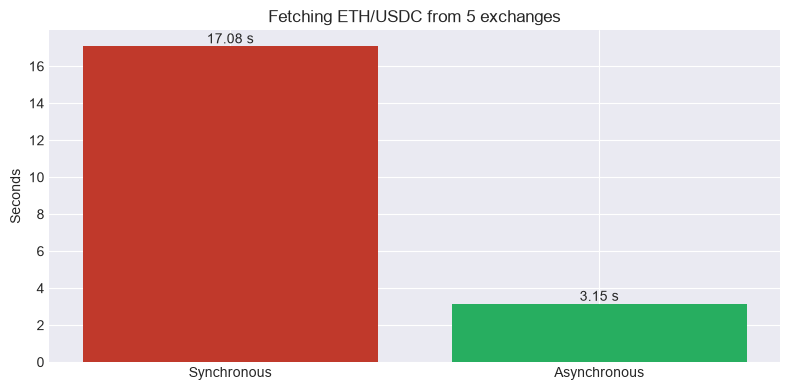

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(["Synchronous", "Asynchronous"], [sync_seconds, async_seconds], color=["#c0392b", "#27ae60"])
ax.bar_label(bars, fmt="%.2f s")
ax.set_ylabel("Seconds")
ax.set_title(f"Fetching {SYMBOL} from {len(EXCHANGES)} exchanges")
plt.tight_layout()
plt.show()

---
## 3. Binance.us REST API: public endpoints

Public endpoints need no authentication: prices, order books, market information, funding rates. We use **Binance.us** ([API docs](https://docs.binance.us/)), reachable from more regions than binance.com.

### 3a. Order book (`/api/v3/depth`)

`bids` are buy orders (highest first), `asks` are sell orders (lowest first); each level is `[price, quantity]`. The gap between the best bid and the best ask is the **spread**.

In [5]:
BINANCE_US = "https://api.binance.us"

response = requests.get(f"{BINANCE_US}/api/v3/depth", params={"symbol": "ETHUSDC", "limit": 5}, timeout=15)
response.raise_for_status()
depth = response.json()

book = pd.DataFrame({
    "bid_price": [float(p) for p, _ in depth["bids"]],
    "bid_qty": [float(q) for _, q in depth["bids"]],
    "ask_price": [float(p) for p, _ in depth["asks"]],
    "ask_qty": [float(q) for _, q in depth["asks"]],
})
display(book)

best_bid, best_ask = book["bid_price"].iloc[0], book["ask_price"].iloc[0]
mid = (best_bid + best_ask) / 2
print(f"Best bid {best_bid:,.2f} | best ask {best_ask:,.2f} | spread {(best_ask - best_bid) / mid * 10_000:.2f} bps")

,bid_price,bid_qty,ask_price,ask_qty
0,"2,303.4600",0.7751,"2,304.5200",0.2478
1,"2,303.4500",0.0117,"2,304.5500",0.0116
2,"2,302.8900",6.0373,"2,305.0100",5.4120
3,"2,302.8000",0.0942,"2,305.2100",0.0938
4,"2,302.6800",0.0944,"2,305.5800",0.1307


Best bid 2,303.46 | best ask 2,304.52 | spread 4.60 bps


### 3b. Average price (`/api/v3/avgPrice`)

Volume-weighted average price of the last `mins` minutes, computed by the exchange.

In [6]:
response = requests.get(f"{BINANCE_US}/api/v3/avgPrice", params={"symbol": "ETHUSDC"}, timeout=15)
response.raise_for_status()
print(response.json())

{'mins': 5, 'price': '2313.73000000', 'closeTime': 1793045003682}


---
## 4. Private endpoints: signed requests (HMAC-SHA256)

Endpoints that move funds, read balances or trade require **authentication**:

1. Build the query string, including a `timestamp` (and optionally `recvWindow`, how long the request stays valid)
2. Sign it with the **API secret** using HMAC-SHA256
3. Send it with `signature=<hex>` appended and the **API key** in the `X-MBX-APIKEY` header

The secret never travels: the exchange recomputes the signature with its own copy and compares. Below we sign Binance's documentation example with an obviously **fake** secret; the request is **not sent**.

In [7]:
# DEMO credentials, obviously fake: they are not valid anywhere
DEMO_API_KEY = "dummy-api-key-for-demo"
DEMO_SECRET = "dummy-secret-for-demo"

params = {
    "symbol": "LTCBTC",
    "side": "BUY",
    "type": "LIMIT",
    "timeInForce": "GTC",
    "quantity": "1",
    "price": "0.1",
    "recvWindow": "5000",
    "timestamp": "1499827319559",   # fixed, from the docs example; a real request uses int(time.time() * 1000)
}


def sign(query_string, secret):
    # HMAC-SHA256 of the query string, hex encoded (what Binance expects in `signature`)
    return hmac.new(secret.encode(), query_string.encode(), hashlib.sha256).hexdigest()


query_string = "&".join(f"{key}={value}" for key, value in params.items())
signature = sign(query_string, DEMO_SECRET)

print("Query:    ", query_string)
print("Signature:", signature)
print("Header:   ", {"X-MBX-APIKEY": DEMO_API_KEY})
# requests.post(f"{BINANCE_US}/api/v3/order", headers=..., data={**params, "signature": signature})  <- NOT sent

Query:     symbol=LTCBTC&side=BUY&type=LIMIT&timeInForce=GTC&quantity=1&price=0.1&recvWindow=5000&timestamp=1499827319559
Signature: 9b7fb1c8e4b2d1fc7d2a82496339fffec0127a089cf43620a89b678fd68d75e0
Header:    {'X-MBX-APIKEY': 'dummy-api-key-for-demo'}


### 4a. A real private call (optional)

Reads the keys from `BINANCE_API_KEY` / `BINANCE_API_SECRET`; without them the cell skips itself. **Never** write keys in the notebook: cell outputs and the source end up in git.

In [8]:
API_KEY = os.environ.get("BINANCE_API_KEY")
API_SECRET = os.environ.get("BINANCE_API_SECRET")

if not (API_KEY and API_SECRET):
    print("[INFO] set BINANCE_API_KEY/BINANCE_API_SECRET to run this cell")
else:
    query = f"timestamp={int(time.time() * 1000)}&recvWindow=5000"
    response = requests.get(f"{BINANCE_US}/api/v3/account", params=f"{query}&signature={sign(query, API_SECRET)}",
                            headers={"X-MBX-APIKEY": API_KEY}, timeout=15)
    if response.status_code == 200:
        print([b for b in response.json()["balances"] if float(b["free"]) > 0])
    else:
        print("[INFO] status", response.status_code)

[INFO] set BINANCE_API_KEY/BINANCE_API_SECRET to run this cell


---
## 5. CCXT: one interface for many exchanges

Every exchange has its own URLs, symbols (`ETHUSDC`, `ETH-USDC`, `XETHZUSD`...) and response formats. **CCXT** standardizes them: the same method names and the same output structure everywhere. We connect to Binance.us with no keys (public data only).

In [9]:
binance = ccxt.binanceus()
ticker = binance.fetch_ticker(SYMBOL)

print(f"{SYMBOL} on {binance.name}")
for field in ("last", "bid", "ask", "high", "low", "baseVolume", "datetime"):
    print(f"  {field:>10}: {ticker[field]}")

ETH/USDC on Binance US
        last: 2313.73
         bid: 2303.46
         ask: 2304.52
        high: 2344.65
         low: 2298.27
  baseVolume: 5.6923
    datetime: 2026-10-26T21:05:25.563Z


### 5a. Order book, the standardized way

In [10]:
order_book = binance.fetch_order_book(SYMBOL, limit=5)
pd.DataFrame({
    "bid_price": [level[0] for level in order_book["bids"]],
    "bid_qty": [level[1] for level in order_book["bids"]],
    "ask_price": [level[0] for level in order_book["asks"]],
    "ask_qty": [level[1] for level in order_book["asks"]],
})

,bid_price,bid_qty,ask_price,ask_qty
0,"2,303.0100",0.3150,"2,304.0900",0.9436
1,"2,303.0000",0.0116,"2,304.1000",0.0117
2,"2,302.5100",6.6063,"2,304.4500",0.0935
3,"2,302.0800",0.0941,"2,304.6200",0.0951
4,"2,301.9800",0.0951,"2,304.8600",0.0950


### 5b. OHLCV candles

`fetch_ohlcv` returns `[timestamp_ms, open, high, low, close, volume]` per candle. We pull one week of hourly candles and plot the close.

,open,high,low,close,volume
timestamp,,,,,
2026-10-26 17:00:00+00:00,"2,315.7900","2,315.7900","2,315.7900","2,315.7900",0.0000
2026-10-26 18:00:00+00:00,"2,318.8100","2,318.8100","2,312.9900","2,312.9900",0.0233
2026-10-26 19:00:00+00:00,"2,312.9900","2,312.9900","2,312.9900","2,312.9900",0.0000
2026-10-26 20:00:00+00:00,"2,313.7300","2,313.7300","2,313.7300","2,313.7300",0.0116
2026-10-26 21:00:00+00:00,"2,313.7300","2,313.7300","2,313.7300","2,313.7300",0.0000


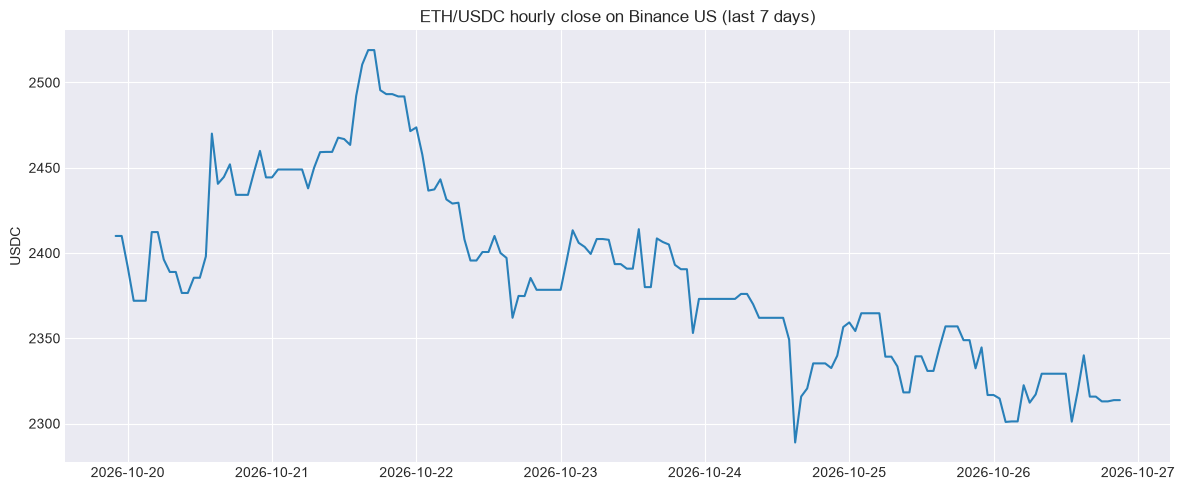

In [11]:
candles = binance.fetch_ohlcv(SYMBOL, "1h", limit=24 * 7)
ohlcv = pd.DataFrame(candles, columns=["timestamp", "open", "high", "low", "close", "volume"])
ohlcv["timestamp"] = pd.to_datetime(ohlcv["timestamp"], unit="ms", utc=True)
ohlcv = ohlcv.set_index("timestamp")
display(ohlcv.tail())

fig, ax = plt.subplots()
ax.plot(ohlcv.index, ohlcv["close"], color="#2980b9", linewidth=1.5)
ax.set_title(f"{SYMBOL} hourly close on {binance.name} (last 7 days)")
ax.set_ylabel("USDC")
plt.tight_layout()
plt.show()

### 5c. The same code on every exchange

Because the interface is standard, comparing exchanges is a loop (we reuse the mid prices fetched concurrently in section 2). We compare **mids**, not `last`: on a thin market the last trade can be minutes old. The cross-exchange spread is the first signal of an arbitrage opportunity (before fees, transfers and withdrawal limits).

In [12]:
prices = pd.Series({ex: p for ex, p in async_prices.items() if p}, name="mid_price").sort_values()
display(prices.to_frame())
print(f"Cross-exchange spread: {(prices.max() - prices.min()) / prices.mean() * 10_000:.1f} bps "
      f"(cheapest {prices.idxmin()}, most expensive {prices.idxmax()})")

,mid_price
coinbase,"2,302.9800"
bybit,"2,303.7250"
binanceus,"2,303.9900"
kraken,"2,304.1400"
okx,"2,304.1550"


Cross-exchange spread: 5.1 bps (cheapest coinbase, most expensive okx)


### 5d. Private data with CCXT (optional)

In [13]:
if not (API_KEY and API_SECRET):
    print("[INFO] set BINANCE_API_KEY/BINANCE_API_SECRET to run this cell")
else:
    private_binance = ccxt.binanceus({"apiKey": API_KEY, "secret": API_SECRET})
    print({asset: amount for asset, amount in private_binance.fetch_balance()["total"].items() if amount})

[INFO] set BINANCE_API_KEY/BINANCE_API_SECRET to run this cell


---
## 6. CEX vs DEX: SushiSwap and QuickSwap on Polygon

SushiSwap and QuickSwap are **forks of Uniswap V2**: same contracts, different addresses. So one class (an *interface*) works for both. We read the pools through public, keyless RPC (override with `RPC_URL_POLYGON`), with the ABIs saved next to this notebook.

- `getAmountsOut(amountIn, path)`: what the router would pay for 1 WETH, **after** the 0.3% fee and price impact
- `getReserves()` of the pair: the mid price is `reserve_quote / reserve_base` (no fee, no impact)

Note: the liquid V2 pools on Polygon use **USDC.e** (bridged, `0x2791...`), not native USDC.

In [14]:
provider_url = os.environ.get("RPC_URL_POLYGON", "https://polygon-bor-rpc.publicnode.com")
w3 = Web3(Web3.HTTPProvider(provider_url, request_kwargs={"timeout": 20}))
w3.middleware_onion.inject(ExtraDataToPOAMiddleware, layer=0)   # Polygon is a PoA chain

ROUTER_ABI = json.loads(Path("router_abi.json").read_text())
FACTORY_ABI = json.loads(Path("factory_abi.json").read_text())
PAIR_ABI = json.loads(Path("pair_abi.json").read_text())

WETH = {"address": Web3.to_checksum_address("0x7ceB23fD6bC0adD59E62ac25578270cFf1b9f619"), "decimals": 18}
USDC_E = {"address": Web3.to_checksum_address("0x2791Bca1f2de4661ED88A30C99A7a9449Aa84174"), "decimals": 6}


class UniswapV2Exchange:
    # One Uniswap-V2-style DEX: a router (quotes, swaps) and a factory (finds the pair of two tokens)

    def __init__(self, name, router_address, factory_address):
        self.name = name
        self.router = w3.eth.contract(address=Web3.to_checksum_address(router_address), abi=ROUTER_ABI)
        self.factory = w3.eth.contract(address=Web3.to_checksum_address(factory_address), abi=FACTORY_ABI)

    def get_output_amount(self, amount_in, token_in, token_out):
        # Tokens out for amount_in (raw units), fee and price impact included
        amounts = self.router.functions.getAmountsOut(amount_in, [token_in["address"], token_out["address"]]).call()
        return amounts[-1] / 10 ** token_out["decimals"]

    def get_mid_price(self, base, quote):
        # Price of 1 base in quote from the pool reserves (token0/token1 order must be checked)
        pair = w3.eth.contract(address=self.factory.functions.getPair(base["address"], quote["address"]).call(), abi=PAIR_ABI)
        reserve0, reserve1, _ = pair.functions.getReserves().call()
        if pair.functions.token0().call() == base["address"]:
            base_reserve, quote_reserve = reserve0, reserve1
        else:
            base_reserve, quote_reserve = reserve1, reserve0
        return (quote_reserve / 10 ** quote["decimals"]) / (base_reserve / 10 ** base["decimals"])


dexes = [
    UniswapV2Exchange("SushiSwap", "0x1b02dA8Cb0d097eB8D57A175b88c7D8b47997506", "0xc35DADB65012eC5796536bD9864eD8773aBc74C4"),
    UniswapV2Exchange("QuickSwap", "0xa5E0829CaCEd8fFDD4De3c43696c57F7D7A678ff", "0x5757371414417b8C6CAad45bAeF941aBc7d3Ab32"),
]
print("Polygon block:", w3.eth.block_number)

Polygon block: 96228908


### 6a. All venues side by side

In [15]:
rows = []
for dex in dexes:
    rows.append({"venue": dex.name, "type": "DEX (Polygon)",
                 "mid_price": dex.get_mid_price(WETH, USDC_E),
                 "sell_1_ETH": dex.get_output_amount(10 ** WETH["decimals"], WETH, USDC_E)})
for exchange_id in ("binanceus", "kraken"):
    book = getattr(ccxt, exchange_id)({"timeout": 10_000}).fetch_order_book(SYMBOL, limit=5)
    rows.append({"venue": exchange_id, "type": "CEX",
                 "mid_price": (book["bids"][0][0] + book["asks"][0][0]) / 2,
                 "sell_1_ETH": book["bids"][0][0]})   # selling 1 ETH hits the best bid (assuming it has >= 1 ETH)

venues = pd.DataFrame(rows).set_index("venue")
reference = venues.loc["binanceus", "mid_price"]
venues["vs_binanceus_bps"] = (venues["mid_price"] / reference - 1) * 10_000
venues

,type,mid_price,sell_1_ETH,vs_binanceus_bps
venue,,,,
SushiSwap,DEX (Polygon),"2,309.8091","2,210.0035",30.4589
QuickSwap,DEX (Polygon),"2,309.2771","2,297.5138",28.1490
binanceus,CEX,"2,302.7950","2,302.2900",0.0000
kraken,CEX,"2,302.6700","2,302.4900",-0.5428


### 6b. Visualization

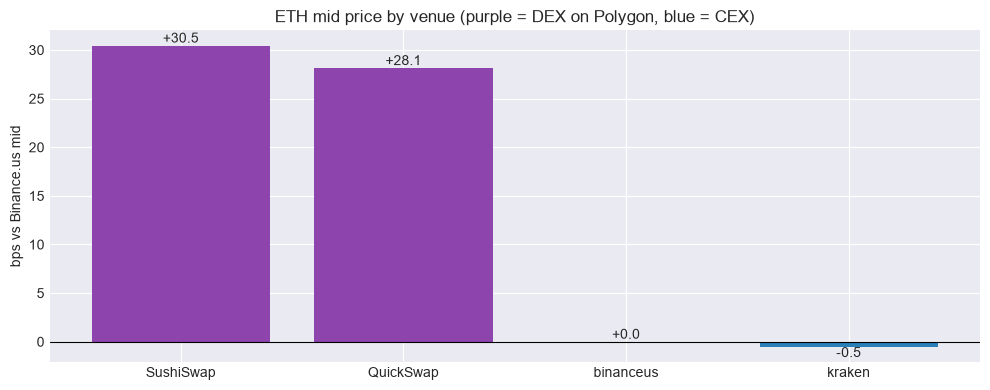

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#8e44ad" if kind.startswith("DEX") else "#2980b9" for kind in venues["type"]]
bars = ax.bar(venues.index, venues["vs_binanceus_bps"], color=colors)
ax.bar_label(bars, fmt="%+.1f")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("bps vs Binance.us mid")
ax.set_title("ETH mid price by venue (purple = DEX on Polygon, blue = CEX)")
plt.tight_layout()
plt.show()

---
## 7. Key Findings

Numbers below are from this run ("at the time of writing (Oct 2026)"; they change on every run).

In [17]:
print(f"1. asyncio: {len(EXCHANGES)} exchanges in {async_seconds:.2f} s concurrently vs {sync_seconds:.2f} s one by one")
print(f"2. Binance.us ETH/USDC spread at the top of the book: {(best_ask - best_bid) / mid * 10_000:.2f} bps")
print(f"3. Cross-CEX spread: {(prices.max() - prices.min()) / prices.mean() * 10_000:.1f} bps")
dex_vs_cex = venues.loc[[d.name for d in dexes], "vs_binanceus_bps"]
print(f"4. DEX mid vs Binance.us: " + ", ".join(f"{name} {bps:+.1f} bps" for name, bps in dex_vs_cex.items()))
for k, name in enumerate(d.name for d in dexes):
    cost_bps = (1 - venues.loc[name, "sell_1_ETH"] / venues.loc[name, "mid_price"]) * 10_000
    print(f"{5 + k}. Selling 1 ETH on {name}: {cost_bps:.0f} bps below its mid (30 bps fee + price impact of a {'thin' if cost_bps > 60 else 'deep'} pool)")

1. asyncio: 5 exchanges in 3.15 s concurrently vs 17.08 s one by one
2. Binance.us ETH/USDC spread at the top of the book: 4.60 bps
3. Cross-CEX spread: 5.1 bps
4. DEX mid vs Binance.us: SushiSwap +30.5 bps, QuickSwap +28.1 bps
5. Selling 1 ETH on SushiSwap: 432 bps below its mid (30 bps fee + price impact of a thin pool)
6. Selling 1 ETH on QuickSwap: 51 bps below its mid (30 bps fee + price impact of a deep pool)


---
## Summary

**What we learned:**
1. `asyncio` turns *n* network waits into one: essential to watch many venues at once
2. Exchange REST APIs: public endpoints need nothing; private ones need an HMAC-SHA256 signature with the secret, and the API key in a header
3. CCXT gives one interface (`fetch_ticker`, `fetch_order_book`, `fetch_ohlcv`, `fetch_balance`) for 100+ exchanges
4. Uniswap V2 forks share one interface too: the same class reads SushiSwap and QuickSwap
5. Prices differ between CEXes and DEXes; whether that is an opportunity depends on fees, price impact, gas and transfer times

**Live version:** `python clase_2.py --blocks 3 --seconds 30` prints the SushiSwap vs QuickSwap spread on every new Polygon block (websocket subscription).

---
### Tarea propuesta

Desarrollar un servicio que, ante cada evento de **swap** de un par determinado (por ejemplo, WMATIC/USDC), muestre el precio actual del par en **SushiSwap, QuickSwap, Binance y OKX**.

Guía:
- Para obtener la dirección del pool: crear el contrato *factory* de UniV2 de SushiSwap y de QuickSwap y llamar a `getPair` con las direcciones de los dos tokens
- Las direcciones de los tokens están en la sección de pools de SushiSwap (filtrar por Polygon y buscar WMATIC/USDC)
- Crear un filtro de web3 con el evento `Swap` y las direcciones del par en los dos protocolos
- En cada evento, imprimir los precios de los 4 exchanges (los CEX con CCXT)